In [1]:
# 本 notebook 展示防守型策略研究的结果。数据来自 research.py 生成的 results/research/*.csv：
#   先在项目根目录运行  python research.py  （重新跑全部研究），再从上到下运行本 notebook。
# 研究目标：长期最大回撤不超过 20%，在此前提下收益尽量高；不追求在牛市里跑赢一直持有。
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import LogLocator, NullFormatter
from pathlib import Path

R = Path("../results/research")
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # 四种系列颜色（已检查色盲可辨识）
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"


def load(name, **kw):
    return pd.read_csv(R / f"{name}.csv", encoding="utf-8-sig", **kw)


def new_fig(height=4.5, rows=1):
    fig, axes = plt.subplots(rows, 1, figsize=(10, height * rows), facecolor=SURFACE, squeeze=False)
    return fig, axes[:, 0]


def style(ax, title=None, pct_y=False):
    """统一样式：浅色背景、只留横向网格线、去掉多余边框。"""
    ax.set_facecolor(SURFACE)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.tick_params(colors=INK2)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    if title:
        ax.set_title(title, loc="left", color=INK, fontsize=12)
    if pct_y:
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")


def end_labels(ax, items, fmt="{:.0%}", log=False):
    """在线的末端标出数值：items = [(x, y, color), ...]；数字太近时往上错开。"""
    low, high = ax.get_ylim()
    span = (np.log10(high) - np.log10(low)) if log else (high - low)
    gap = span * 0.07
    pos = lambda y: np.log10(y) if log else y
    prev = None
    for x, y, color in sorted(items, key=lambda t: t[1]):
        p = pos(y) if prev is None else max(pos(y), prev + gap)
        prev = p
        yy = 10 ** p if log else p
        ax.scatter([x], [yy], s=22, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=4, clip_on=False)
        ax.annotate(fmt.format(y), (x, yy), xytext=(7, 0), textcoords="offset points", va="center",
                    fontsize=9, color=INK, annotation_clip=False)


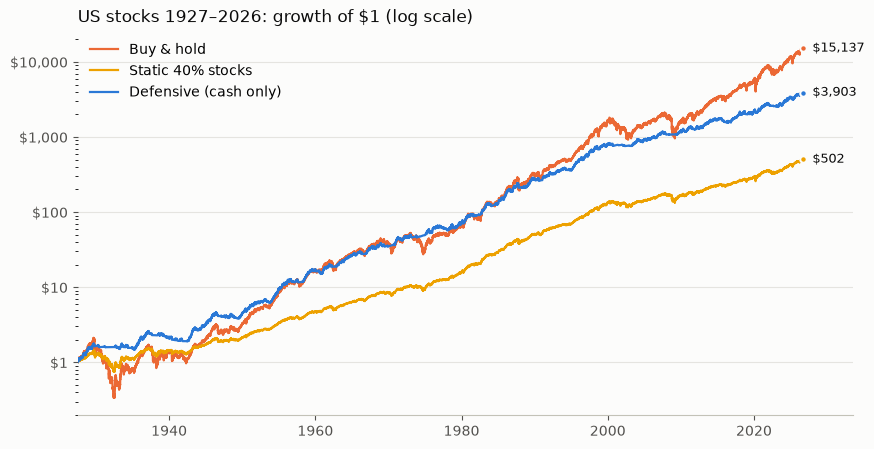

In [2]:
# 策略：比较美国股市 1927–2026 年（100 年）里三种做法（每天收盘后算信号，第二天收盘成交，每次交易成本 0.1%）：
#   Buy & hold：一直满仓持有股票
#   Static 40%：固定 40% 股票 + 60% 现金（“少买一点股票”这种最简单的防守）
#   Defensive (cash only)：终选方案的“无国债”版本——
#       股票仓位 = 趋势信号 × min(1, 10% ÷ 最近 20 日年化波动)
#         趋势信号 = 100/150/200/250/300 日五条均线里“价格在均线之上”的比例（0~1），各带 1% 缓冲
#       其余全部现金（1962 年以前没有国债数据，所以这里不含国债；含国债的版本见后面几张图）
# 买入：美国全市场股票（弗伦奇数据库：纽交所+美交所+纳斯达克全部股票按市值加权，含分红）；
#       现金按 1 个月国库券利率计息。初始 1 美元。
#
# 图：账户净值，对数刻度（同样的百分比涨跌在图上高度相同，适合看长期）。
eq = load("long_equity", index_col=0, parse_dates=True)
lines = [("一直持有", "Buy & hold", ORANGE), ("静态40%股票", "Static 40% stocks", YELLOW),
         ("终选方案(无国债)", "Defensive (cash only)", BLUE)]
fig, (ax,) = new_fig(5)
for col, label, color in lines:
    ax.plot(eq.index, eq[col], color=color, linewidth=1.6, label=label)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:,.0f}" if v >= 1 else f"${v:.1f}")
style(ax, "US stocks 1927–2026: growth of $1 (log scale)")
ax.set_xlim(eq.index[0], eq.index[-1] + pd.Timedelta(days=2500))
end_labels(ax, [(eq.index[-1], eq[c].iloc[-1], color) for c, _, color in lines], fmt="${:,.0f}", log=True)
ax.legend(loc="upper left", frameon=False)
plt.show()


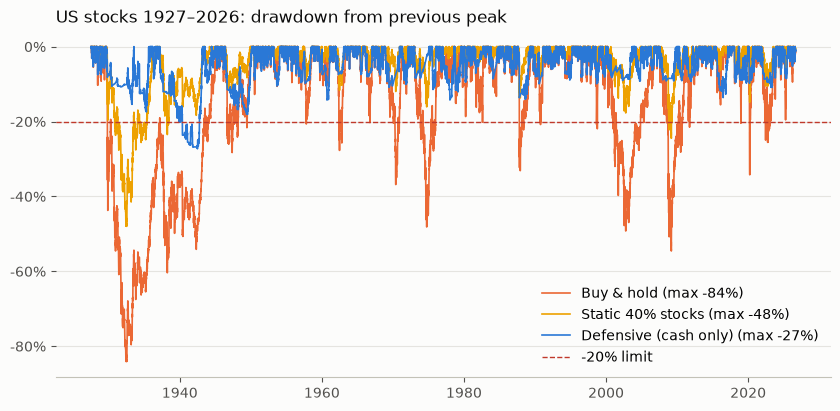

In [3]:
# 策略：同上三种做法（美国股市 1927–2026，空仓持有现金）。
# 买入：美国全市场股票（弗伦奇数据库，含分红）+ 现金。
#
# 图：回撤曲线——每天比历史最高点低了多少。越往下越痛；红色虚线是你能接受的 -20%。
eq = load("long_equity", index_col=0, parse_dates=True)
dd = eq / eq.cummax() - 1
fig, (ax,) = new_fig(4.5)
for col, label, color in [("一直持有", "Buy & hold", ORANGE), ("静态40%股票", "Static 40% stocks", YELLOW),
                          ("终选方案(无国债)", "Defensive (cash only)", BLUE)]:
    ax.plot(dd.index, dd[col], color=color, linewidth=1.2, label=f"{label} (max {dd[col].min():.0%})")
ax.axhline(-0.20, color="#c0392b", linewidth=1, linestyle="--", label="-20% limit")
style(ax, "US stocks 1927–2026: drawdown from previous peak", pct_y=True)
ax.legend(loc="lower right", frameon=False, ncol=1)
plt.show()


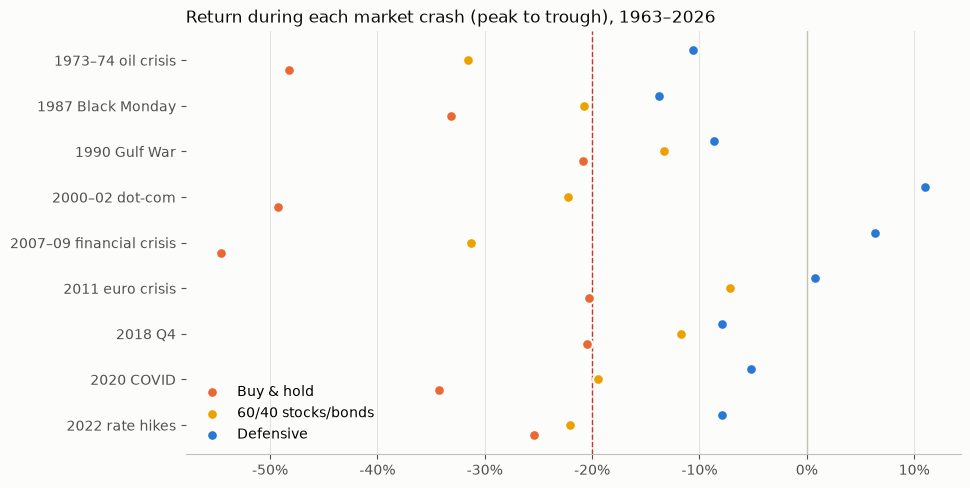

In [4]:
# 策略：美国股票 + 国债，1963–2026（每天收盘后算信号，第二天收盘成交，每次交易成本 0.1%）：
#   Buy & hold：一直满仓持有股票
#   60/40：固定 60% 股票 + 40% 国债（最常见的“平衡型”组合）
#   Defensive（终选方案）：每天收盘后，
#       股票仓位 = 趋势信号 × min(1, 10% ÷ 最近 20 日年化波动)
#         趋势信号 = 100/150/200/250/300 日五条均线里“价格在均线之上”的比例（0~1），各带 1% 缓冲
#       剩余资金 → 国债（只在国债高于自己的 200 日均线时），否则留作现金
# 买入：美国全市场股票（弗伦奇数据库，含分红）+ 10 年期美国国债（用 FRED 的 10 年期国债收益率逐日合成的
#       总回报，含利息）；现金按国库券利率计息。
#
# 图：美股历次大跌期间（从市场高点到低点），三种做法各自的累计收益。
cr = load("bond_crises", index_col=0)
names = [("一直持有股票", "Buy & hold", ORANGE), ("60/40股债", "60/40 stocks/bonds", YELLOW), ("终选方案", "Defensive", BLUE)]
crises = list(cr.columns)[::-1]
labels_en = {"1973 石油危机": "1973–74 oil crisis", "1987 黑色星期一": "1987 Black Monday", "1990 海湾战争": "1990 Gulf War",
             "2000 互联网泡沫": "2000–02 dot-com", "2008 金融危机": "2007–09 financial crisis", "2011 欧债危机": "2011 euro crisis",
             "2018 四季度": "2018 Q4", "2020 新冠": "2020 COVID", "2022 加息熊市": "2022 rate hikes"}
fig, (ax,) = new_fig(5.5)
y = np.arange(len(crises))
for k, (row, label, color) in enumerate(names):
    vals = cr.loc[row, crises].astype(float).to_numpy()
    ax.scatter(vals, y + (k - 1) * 0.22, s=60, color=color, edgecolor=SURFACE, linewidth=1.5, label=label, zorder=3)
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.axvline(-0.20, color="#c0392b", linewidth=1, linestyle="--")
ax.set_yticks(y, [labels_en[c] for c in crises])
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
style(ax, "Return during each market crash (peak to trough), 1963–2026")
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", frameon=False)
plt.show()


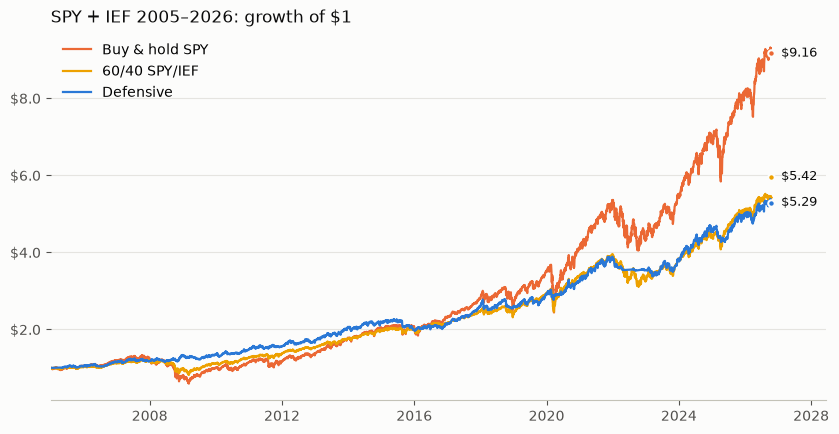

In [5]:
# 策略：可以实际交易的 ETF，2005–2026（每天收盘后算信号，第二天开盘成交，每次交易成本 0.05%）：
#   Buy & hold SPY：一直满仓持有 SPY
#   60/40：固定 60% SPY + 40% IEF
#   Defensive（终选方案）：每天收盘后，
#       股票仓位 = 趋势信号 × min(1, 10% ÷ 最近 20 日年化波动)
#         趋势信号 = 100/150/200/250/300 日五条均线里“价格在均线之上”的比例（0~1），各带 1% 缓冲
#       剩余资金 → IEF（只在 IEF高于自己的 200 日均线时），否则留作现金
# 买入：SPY（标普 500 ETF）、IEF（7–10 年期美国国债 ETF），价格为复权日线（含分红）；现金按国库券利率计息。
#
# 图：账户净值（初始 1 美元）。
eq = load("etf_equity", index_col=0, parse_dates=True)
lines = [("一直持有SPY", "Buy & hold SPY", ORANGE), ("60/40", "60/40 SPY/IEF", YELLOW), ("终选方案", "Defensive", BLUE)]
fig, (ax,) = new_fig(4.8)
for col, label, color in lines:
    ax.plot(eq.index, eq[col], color=color, linewidth=1.6, label=label)
style(ax, "SPY + IEF 2005–2026: growth of $1")
ax.yaxis.set_major_formatter(lambda v, _: f"${v:.1f}")
ax.set_xlim(eq.index[0], eq.index[-1] + pd.Timedelta(days=600))
end_labels(ax, [(eq.index[-1], eq[c].iloc[-1], color) for c, _, color in lines], fmt="${:.2f}")
ax.legend(loc="upper left", frameon=False)
plt.show()


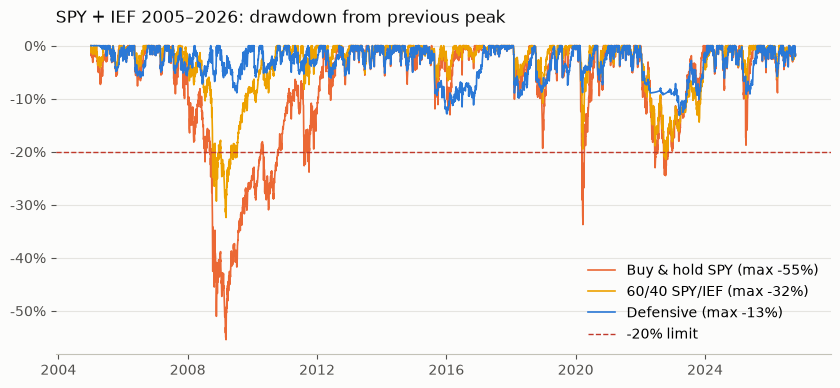

In [6]:
# 策略：同上（SPY + IEF，2005–2026，第二天开盘成交）。
# 买入：SPY、IEF（复权日线）+ 现金。
#
# 图：回撤曲线。红色虚线是 -20%。
dd = load("etf_drawdown", index_col=0, parse_dates=True)
fig, (ax,) = new_fig(4.2)
for col, label, color in [("一直持有SPY", "Buy & hold SPY", ORANGE), ("60/40", "60/40 SPY/IEF", YELLOW), ("终选方案", "Defensive", BLUE)]:
    ax.plot(dd.index, dd[col], color=color, linewidth=1.2, label=f"{label} (max {dd[col].min():.0%})")
ax.axhline(-0.20, color="#c0392b", linewidth=1, linestyle="--", label="-20% limit")
style(ax, "SPY + IEF 2005–2026: drawdown from previous peak", pct_y=True)
ax.legend(loc="lower right", frameon=False)
plt.show()


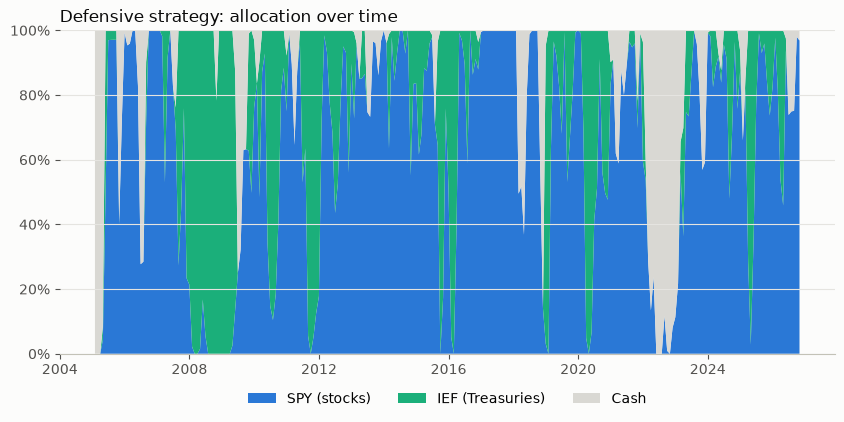

In [7]:
# 策略：终选方案（SPY + IEF，2005–2026）。
#   Defensive（终选方案）：每天收盘后，
#       股票仓位 = 趋势信号 × min(1, 10% ÷ 最近 20 日年化波动)
#         趋势信号 = 100/150/200/250/300 日五条均线里“价格在均线之上”的比例（0~1），各带 1% 缓冲
#       剩余资金 → IEF（只在 IEF高于自己的 200 日均线时），否则留作现金
# 买入：SPY（标普 500 ETF）、IEF（7–10 年期美国国债 ETF）、现金。
#
# 图：三部分各占总资产的比例（每月平均）。可以看到大跌期间（2008、2020、2022）股票仓位如何自动降下来。
h = load("etf_final_holdings", index_col=0, parse_dates=True).resample("ME").mean()  # 按月平均，图更清楚
cash = (1 - h.sum(axis=1)).clip(lower=0)
fig, (ax,) = new_fig(4.2)
ax.stackplot(h.index, h["SPY"], h["IEF"], cash, colors=[BLUE, AQUA, "#d9d8d3"],
             labels=["SPY (stocks)", "IEF (Treasuries)", "Cash"], linewidth=0)
ax.set_ylim(0, 1)
style(ax, "Defensive strategy: allocation over time", pct_y=True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False, ncol=3)
plt.show()


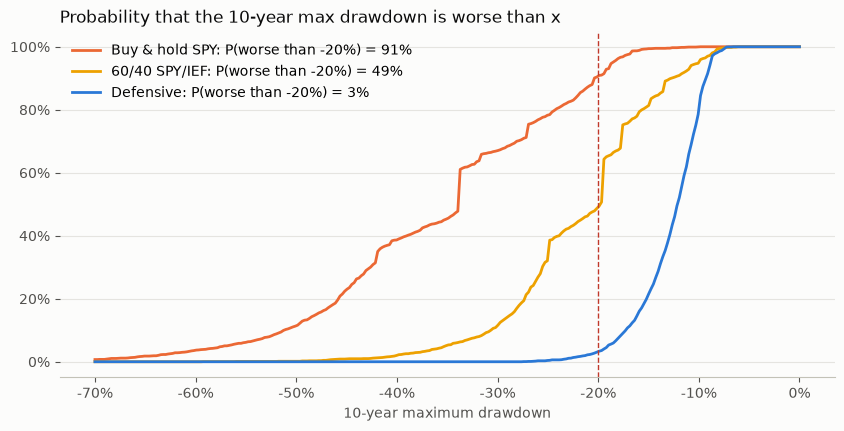

In [8]:
# 策略：同上三种做法（SPY + IEF，2005–2026）。
# 买入：SPY、IEF + 现金。
#
# 图：“未来 10 年最大回撤会有多大”的估计。方法（分块自助法）：从 2005–2026 的历史日收益里随机抽取连续的半年片段，
#     拼成 2000 条“可能的 10 年”，算每条的最大回撤。曲线上每一点 = 最大回撤“比这个数更糟”的概率。
#     例如蓝线在 -20% 处的高度，就是终选方案未来 10 年回撤超过 20% 的估计概率。
b = load("etf_bootstrap_mdd")
fig, (ax,) = new_fig(4.5)
grid = np.linspace(-0.7, 0, 300)
for col, label, color in [("一直持有SPY", "Buy & hold SPY", ORANGE), ("60/40", "60/40 SPY/IEF", YELLOW), ("终选方案", "Defensive", BLUE)]:
    prob = [(b[col] < x).mean() for x in grid]
    ax.plot(grid, prob, color=color, linewidth=2, label=f"{label}: P(worse than -20%) = {(b[col] < -0.2).mean():.0%}")
ax.axvline(-0.20, color="#c0392b", linewidth=1, linestyle="--")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("10-year maximum drawdown", color=INK2)
style(ax, "Probability that the 10-year max drawdown is worse than x", pct_y=True)
ax.legend(loc="upper left", frameon=False)
plt.show()


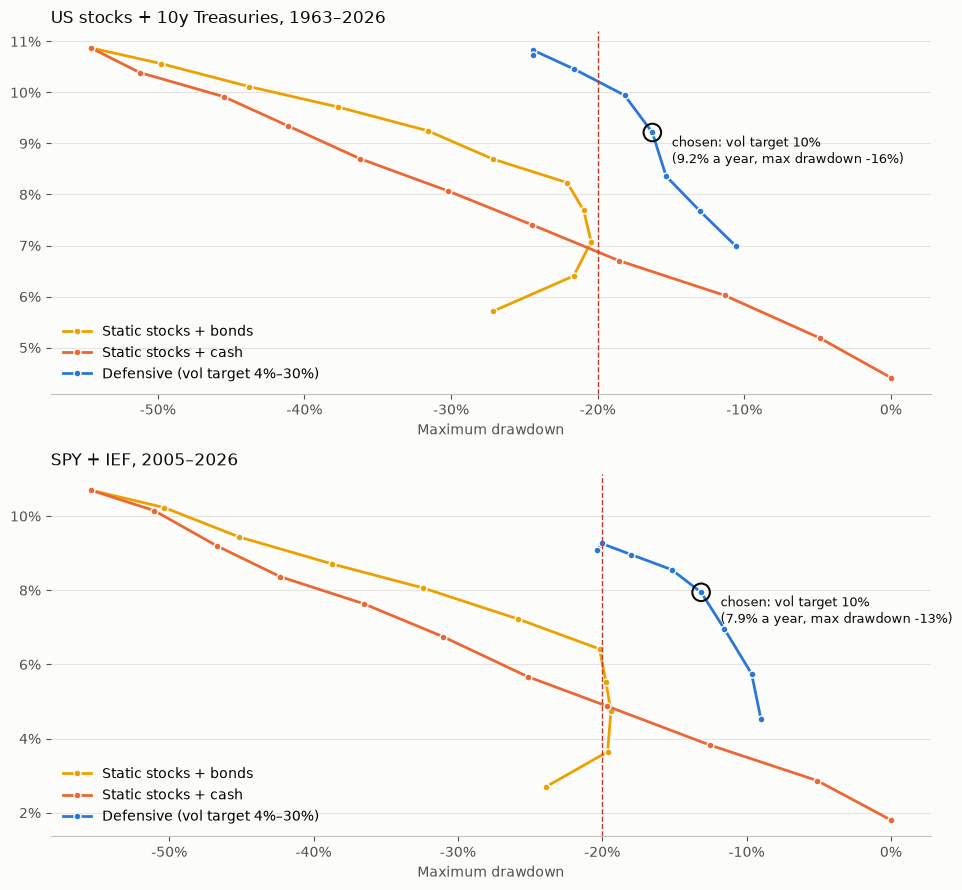

In [9]:
# 策略：两组“同一类做法、不同激进程度”的比较（有效前沿）：
#   Static stocks + bonds：股票占 0%、10%、…、100%，其余国债，固定比例（线从右下 0% 股票连到左上 100% 股票）
#   Static stocks + cash：股票占 0%~100%，其余现金
#   Defensive：终选方案，波动率目标取 4%、6%、8%、10%、12%、15%、20%、30%（越大越激进）
# 买入：上图：美国全市场股票 + 合成 10 年期国债，1963–2026；下图：SPY + IEF，2005–2026。
#
# 图：横轴 = 最大回撤，纵轴 = 年化收益。越靠左上越好（同样回撤下收益更高）。红色虚线 = -20%。
fig, axes = new_fig(4.5, rows=2)
for ax, (tag, title) in zip(axes, [("us1963", "US stocks + 10y Treasuries, 1963–2026"), ("etf2005", "SPY + IEF, 2005–2026")]):
    f = load(f"frontier_{tag}")
    for fam, label, color in [("静态股票+国债", "Static stocks + bonds", YELLOW), ("静态股票+现金", "Static stocks + cash", ORANGE),
                              ("终选方案(不同波动率目标)", "Defensive (vol target 4%–30%)", BLUE)]:
        d = f[f["做法"] == fam].sort_values("参数")  # 按激进程度顺序连线
        ax.plot(d["最大回撤"], d["年化收益"], color=color, linewidth=2, marker="o", markersize=5,
                markeredgecolor=SURFACE, label=label)
    sel = f[(f["做法"] == "终选方案(不同波动率目标)") & (f["参数"].round(2) == 0.10)].iloc[0]
    ax.scatter([sel["最大回撤"]], [sel["年化收益"]], s=160, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=5)
    ax.annotate(f"chosen: vol target 10%\n({sel['年化收益']:.1%} a year, max drawdown {sel['最大回撤']:.0%})",
                (sel["最大回撤"], sel["年化收益"]), xytext=(14, -22), textcoords="offset points", fontsize=9, color=INK)
    ax.axvline(-0.20, color="#c0392b", linewidth=1, linestyle="--")
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    style(ax, title, pct_y=True)
    ax.set_xlabel("Maximum drawdown", color=INK2)
    ax.legend(loc="lower left", frameon=False)
fig.tight_layout()
plt.show()


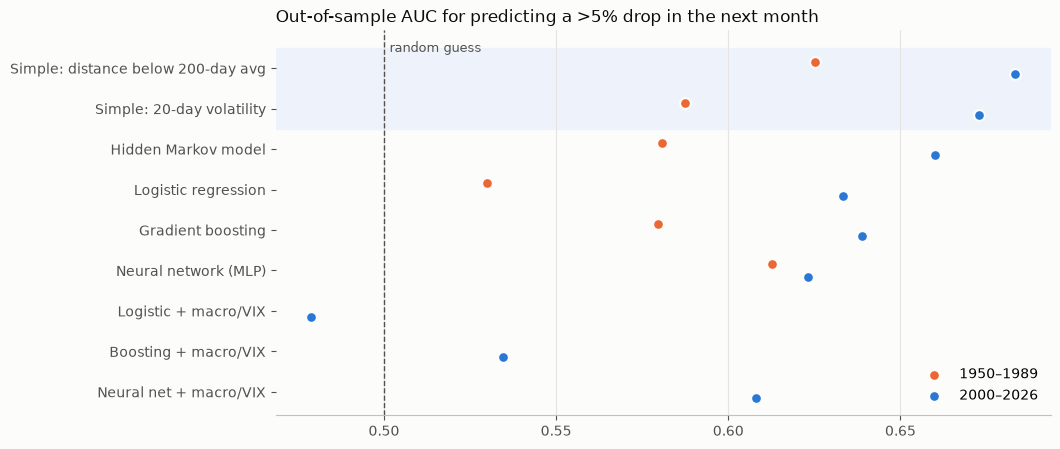

In [10]:
# 策略：训练出来的模型能否预测“未来 21 个交易日累计下跌超过 5%”。全部滚动训练（每年只用过去的数据重新训练）：
#   logit = 逻辑回归，gbm = 梯度提升树，mlp = 神经网络，hmm = 两状态隐马尔可夫模型（动荡状态概率）
#   “+宏观VIX” = 额外加入期限利差、信用利差、VIX 的版本（1990 年起才有数据，2000 年起预测）
#   对照：只看一个简单指标——最近 20 日波动率，或价格低于 200 日均线的幅度
# 买入：不涉及交易；预测对象是美国全市场股票（弗伦奇数据库）。
#
# 图：样本外 AUC（把“会大跌”的日子排在前面的能力：0.5 = 瞎猜，1 = 完美）。
auc = load("models_auc", index_col=0)
order = ["只看离200日均线", "只看波动率", "hmm", "logit", "gbm", "mlp", "logit+宏观VIX", "gbm+宏观VIX", "mlp+宏观VIX"]
names_en = {"只看离200日均线": "Simple: distance below 200-day avg", "只看波动率": "Simple: 20-day volatility",
            "hmm": "Hidden Markov model", "logit": "Logistic regression", "gbm": "Gradient boosting",
            "mlp": "Neural network (MLP)", "logit+宏观VIX": "Logistic + macro/VIX", "gbm+宏观VIX": "Boosting + macro/VIX",
            "mlp+宏观VIX": "Neural net + macro/VIX"}
fig, (ax,) = new_fig(5)
y = np.arange(len(order))[::-1]
for col, label, color, shift in [("1950-1989", "1950–1989", ORANGE, 0.15), ("2000-2026", "2000–2026", BLUE, -0.15)]:
    vals = auc.reindex(order)[col].astype(float)
    ax.scatter(vals, y + shift, s=60, color=color, edgecolor=SURFACE, linewidth=1.5, label=label, zorder=3)
ax.axvline(0.5, color=INK2, linewidth=1, linestyle="--")
ax.annotate("random guess", (0.5, len(order) - 0.6), xytext=(4, 0), textcoords="offset points", fontsize=9, color=INK2)
ax.set_yticks(y, [names_en[o] for o in order])
ax.axhspan(len(order) - 2.5, len(order) - 0.5, color="#eef3fb", zorder=0)
style(ax, "Out-of-sample AUC for predicting a >5% drop in the next month")
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
plt.show()


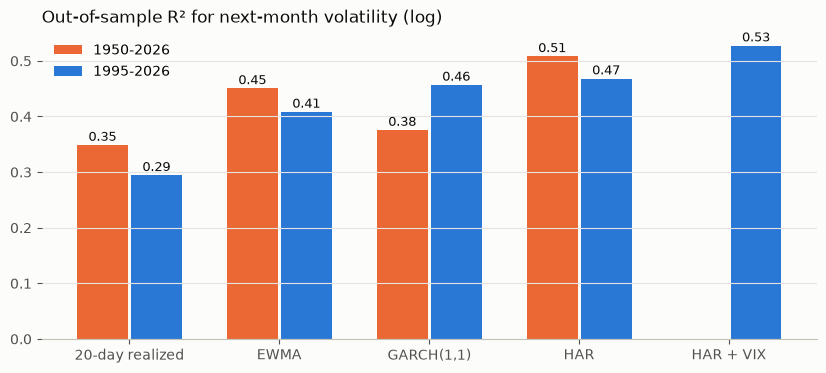

In [11]:
# 策略：比较几种预测“未来 21 个交易日波动率”的方法（全部滚动训练，样本外评价）：
#   rv20 = 最近 20 日波动（基准）；ewma = 指数加权；garch = GARCH(1,1)；har = 日/周/月三尺度波动回归；
#   har_vix = HAR 再加 VIX
# 买入：不涉及交易；预测对象是美国全市场股票（弗伦奇数据库）。
#
# 图：对数波动率的样本外 R²（越高越准）。和之前 ARMA 预测涨跌（R² < 0）对比：波动率是可以预测的。
v = load("models_vol_forecast", index_col=[0, 1])
fig, (ax,) = new_fig(4)
methods = ["rv20", "ewma", "garch", "har", "har_vix"]
x = np.arange(len(methods))
for period, color, shift in [("1950-2026", ORANGE, -0.18), ("1995-2026", BLUE, 0.18)]:
    vals = [v.loc[(period, mth), "R2_对数波动"] if (period, mth) in v.index else np.nan for mth in methods]
    ax.bar(x + shift, vals, width=0.34, color=color, label=period)
    for xi, val in zip(x + shift, vals):
        if not np.isnan(val):
            ax.annotate(f"{val:.2f}", (xi, val), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, ["20-day realized", "EWMA", "GARCH(1,1)", "HAR", "HAR + VIX"])
style(ax, "Out-of-sample R² for next-month volatility (log)")
ax.legend(loc="upper left", frameon=False)
plt.show()


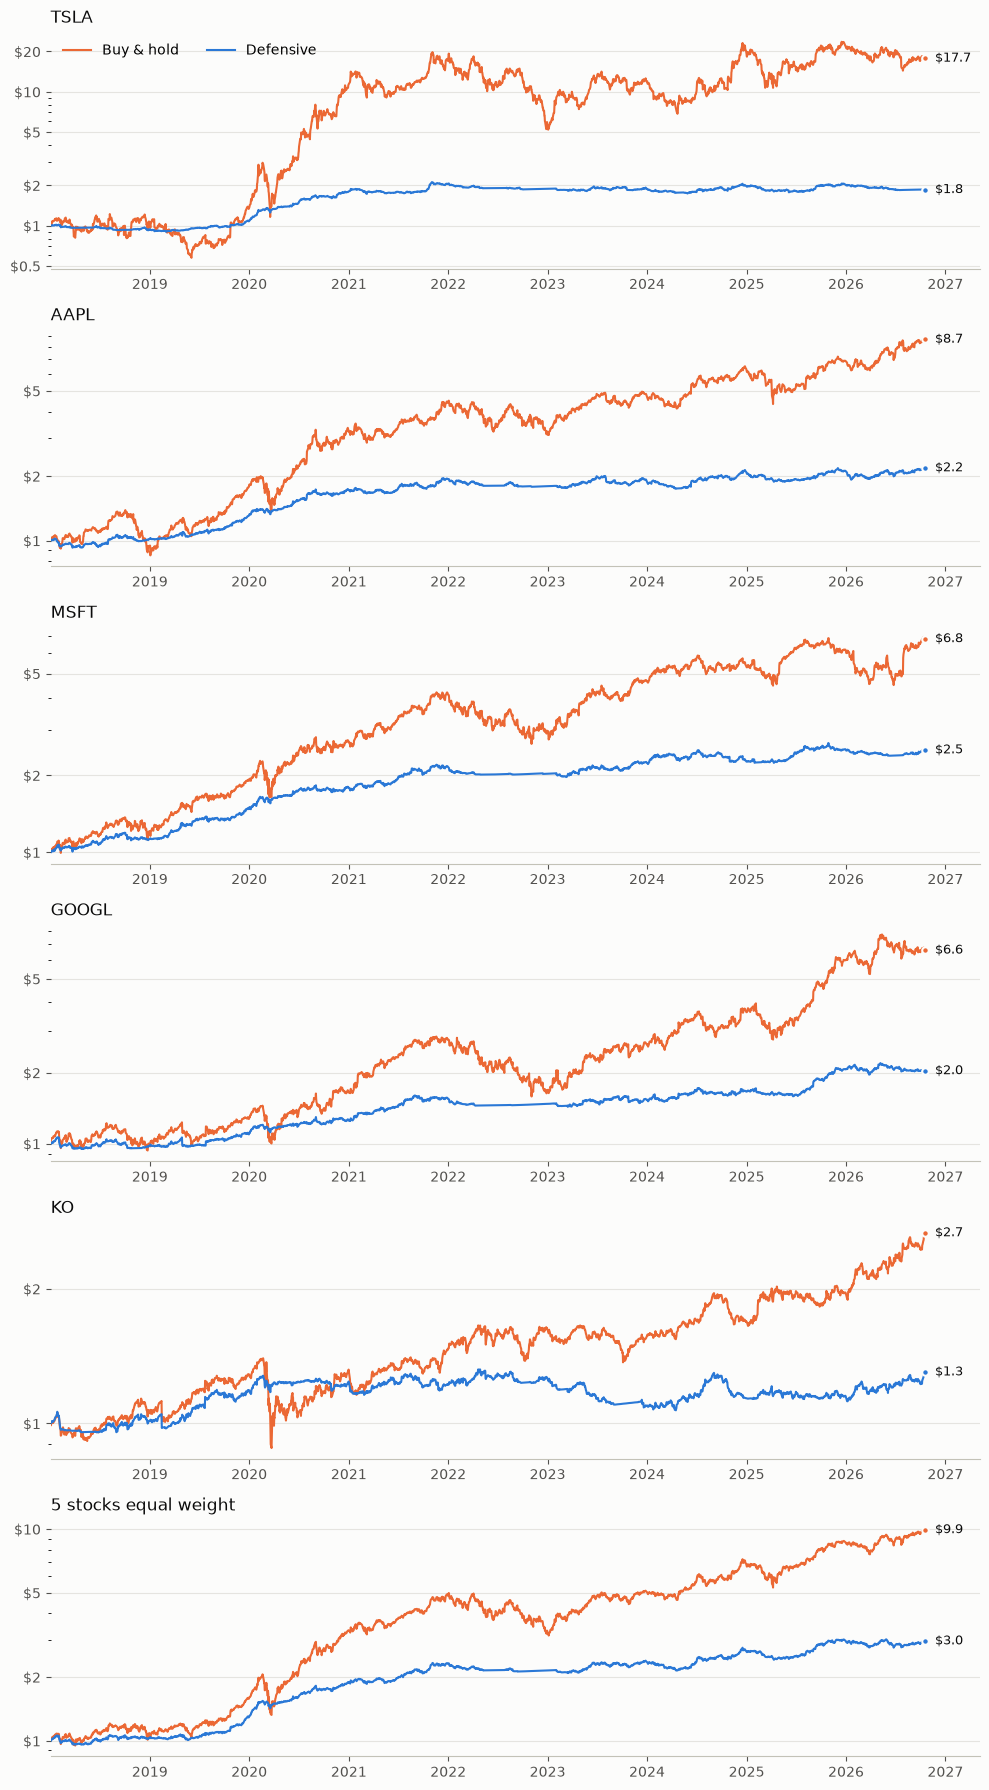

In [12]:
# 策略：把终选方案分别用在你关注的股票上（2018–2026，第二天开盘成交，每次交易成本 0.05%）：
#   Buy & hold：一直满仓持有该股票
#   Defensive（终选方案）：每天收盘后，
#       股票仓位 = 趋势信号 × min(1, 10% ÷ 最近 20 日年化波动)
#         趋势信号 = 100/150/200/250/300 日五条均线里“价格在均线之上”的比例（0~1），各带 1% 缓冲
#       剩余资金 → IEF（只在 IEF高于自己的 200 日均线时），否则留作现金
#   最后一行“5 stocks equal weight”：5 只股票等权（每天再平衡）当作一个整体，再套用终选方案
# 买入：TSLA（特斯拉）、AAPL（苹果）、MSFT（微软）、GOOGL（谷歌 A 类股）、KO（可口可乐），复权日线；
#       IEF（7–10 年期美国国债 ETF）；现金。
#
# 图：每只股票一行，账户净值（初始 1 美元，对数刻度）。
eq = load("stocks_equity", index_col=0, parse_dates=True)
groups = ["TSLA", "AAPL", "MSFT", "GOOGL", "KO", "5只等权"]
fig, axes = new_fig(3.0, rows=len(groups))
for ax, g in zip(axes, groups):
    items = []
    for name, label, color in [("一直持有", "Buy & hold", ORANGE), ("终选方案", "Defensive", BLUE)]:
        s = eq[f"{g}|{name}"].dropna()
        ax.plot(s.index, s, color=color, linewidth=1.5, label=label)
        items.append((s.index[-1], s.iloc[-1], color))
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))  # 刻度：$1 $2 $5 $10 ...
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.yaxis.set_major_formatter(lambda v, _: f"${v:g}")
    style(ax, "5 stocks equal weight" if g == "5只等权" else g)
    ax.set_xlim(s.index[0], s.index[-1] + pd.Timedelta(days=200))
    end_labels(ax, items, fmt="${:.1f}", log=True)
axes[0].legend(loc="upper left", frameon=False, ncol=2)
fig.tight_layout()
plt.show()
